# **Arabic Readability Classification Using Random Forest**

## **Experiment Objective**

The objective of this experiment is to evaluate Random Forest for Arabic readability classification using the BAREC Corpus. The experiment focuses on predicting the readability level of Arabic texts based on their textual features.

The study uses TF-IDF for feature extraction and Random Forest as the classification algorithm. It investigates the baseline model, hyperparameter tuning, and the effect of class weighting on predictive performance.

The experiment also compares the 19-level, 5-level and 4-level classification setups to examine the impact of the number of readability levels on model performance.

## **Why Random Forest?**

Random Forest is an ensemble learning method that combines the predictions of many decision trees, each trained on a bootstrap sample of the data and a random subset of features at each split. Averaging many decorrelated trees reduces variance and makes the model less prone to overfitting than a single decision tree (Breiman, 2001). Random Forest can operate on high-dimensional sparse feature spaces such as TF-IDF representations, supports class weighting for imbalanced data through the `class_weight` parameter, and is known to perform reasonably well with default hyperparameters (Probst et al., 2019). This makes it a strong classical model for Arabic readability classification.


## **1. Data Loading**

This section extracts and loads the preprocessed BAREC dataset for the original classification setup, which contains separate training, development, and test sets.

The existing data splits are preserved without additional preprocessing or resampling. The dataset structure, column names, and sample counts are inspected before proceeding to feature extraction.

### Extracting the Dataset

The prepared dataset is uploaded as a compressed `.zip` file. The code below uses the first `.zip` file found in `/content`; if none is found, it opens an upload dialog. It then extracts the archive and locates the folder that contains `original/train.csv`, so the code works whether or not the archive contains an extra top-level folder.

In [ ]:
import os
import glob
import zipfile

ZIP_PATH = None          # e.g. "/content/BAREC_prepared_datasets.zip" — leave None to detect automatically
EXTRACT_DIR = "/content/BAREC_data"

if ZIP_PATH is None:
    zip_files = glob.glob("/content/*.zip")
    if not zip_files:
        from google.colab import files
        uploaded = files.upload()
        zip_files = [os.path.join("/content", name) for name in uploaded if name.endswith(".zip")]
    if not zip_files:
        raise FileNotFoundError("No .zip file was found or uploaded.")
    ZIP_PATH = zip_files[0]

print("Extracting:", ZIP_PATH)
os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as archive:
    archive.extractall(EXTRACT_DIR)

# Locate the dataset folder (the one containing original/train.csv)
matches = [p for p in glob.glob(os.path.join(EXTRACT_DIR, "**", "original", "train.csv"), recursive=True)
           if "__MACOSX" not in p]
if not matches:
    raise FileNotFoundError("Could not find original/train.csv inside the archive.")

data_dir = os.path.dirname(os.path.dirname(matches[0]))
print("Dataset folder:", data_dir)
print("Contents:", os.listdir(data_dir))

Saving BAREC_prepared_datasets.zip to BAREC_prepared_datasets.zip
Extracting: /content/BAREC_prepared_datasets.zip
Dataset folder: /content/BAREC_data
Contents: ['original', 'merged_4_level']


###  Loading the Dataset Splits

In [ ]:
import pandas as pd
import os
import glob

# Ensure data_dir is defined even if the extraction cell wasn't run in this session
if 'data_dir' not in globals():
    print("data_dir not found in memory. Attempting to locate automatically...")
    matches = [p for p in glob.glob(os.path.join("/content/BAREC_data", "**", "original", "train.csv"), recursive=True)
               if "__MACOSX" not in p]
    if matches:
        data_dir = os.path.dirname(os.path.dirname(matches[0]))
        print(f"Successfully located data_dir: {data_dir}")
    else:
        raise NameError("data_dir is not defined, and the dataset could not be found in /content/BAREC_data. Please run the extraction cell first.")

original_dir = os.path.join(data_dir, "original")

# Load original dataset splits
train_original = pd.read_csv(os.path.join(original_dir, "train.csv"))
dev_original = pd.read_csv(os.path.join(original_dir, "dev.csv"))
test_original = pd.read_csv(os.path.join(original_dir, "test.csv"))

# Inspect dataset structure
datasets = {
    "Original - Train": train_original,
    "Original - Dev": dev_original,
    "Original - Test": test_original,
}

for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(name)
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")


Original - Train
Shape: (54845, 19)
Columns: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class']

Original - Dev
Shape: (7310, 19)
Columns: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class']

Original - Test
Shape: (7286, 19)
Columns: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class']


In [ ]:
# Define input text
rf_X_train = train_original["Word"]
rf_X_dev = dev_original["Word"]
rf_X_test = test_original["Word"]

# Define target labels for 19-level classification
rf_y_train_19 = train_original["Readability_Level_19"]
rf_y_dev_19 = dev_original["Readability_Level_19"]
rf_y_test_19 = test_original["Readability_Level_19"]

# Define target labels for 5-level classification
rf_y_train_5 = train_original["Readability_Level_5"]
rf_y_dev_5 = dev_original["Readability_Level_5"]
rf_y_test_5 = test_original["Readability_Level_5"]

# Define target labels for 4-level classification (5-level labels with levels 4 and 5 merged)
rf_y_train_4 = rf_y_train_5.replace({5: 4})
rf_y_dev_4 = rf_y_dev_5.replace({5: 4})
rf_y_test_4 = rf_y_test_5.replace({5: 4})

print("4-level label distribution (development set):", rf_y_dev_4.value_counts().sort_index().to_dict())

4-level label distribution (development set): {1: 1679, 2: 2270, 3: 1840, 4: 1521}


### Creating the 4-Level Labels

The 4-level labels are created from the 5-level labels by merging the two highest levels: level 5 is relabeled as level 4, and levels 1–3 stay unchanged.

| 5-level label | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| 4-level label | 1 | 2 | 3 | 4 | 4 |

Level 5 is the smallest class (191 of 7,310 development sentences) and is rarely predicted correctly. Merging it with level 4 removes this very small class while keeping the ordinal order of the levels.

## **2. Feature Extraction Using TF-IDF**

The `Word` column is used as the input text representation for the Random Forest model. This representation preserves the original sentence text for readability classification.

TF-IDF (Term Frequency–Inverse Document Frequency) converts the text into numerical feature vectors. Both unigrams and bigrams are included to capture individual words and consecutive word pairs.

The vectorizer is fitted exclusively on the training set and then applied to the development and test sets to prevent information leakage.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer
rf_vectorizer = TfidfVectorizer(ngram_range=(1, 2))

# Fit on training data and transform all splits
rf_X_train_tfidf = rf_vectorizer.fit_transform(rf_X_train)
rf_X_dev_tfidf = rf_vectorizer.transform(rf_X_dev)
rf_X_test_tfidf = rf_vectorizer.transform(rf_X_test)

# Display feature matrix information
print("Training TF-IDF shape:", rf_X_train_tfidf.shape)
print("Development TF-IDF shape:", rf_X_dev_tfidf.shape)
print("Test TF-IDF shape:", rf_X_test_tfidf.shape)
print("Vocabulary size:", len(rf_vectorizer.vocabulary_))

Training TF-IDF shape: (54845, 520826)
Development TF-IDF shape: (7310, 520826)
Test TF-IDF shape: (7286, 520826)
Vocabulary size: 520826


## **3. Model Evaluation**

### 3.1 Evaluation Metrics Overview

The Random Forest models are evaluated using multiple metrics to assess their performance on ordinal Arabic readability classification tasks.

- **Quadratic Weighted Kappa (QWK):** Measures agreement between predicted and actual readability levels while penalizing larger errors more heavily.
- **Accuracy:** Measures the proportion of correctly classified samples.
- **Adjacent Accuracy (±1):** Considers a prediction correct if it falls within one readability level of the actual label.
- **Macro F1-score:** Calculates the average F1-score across all classes, giving equal importance to each class regardless of its size.
- **Weighted Precision:** Measures prediction precision while accounting for the number of samples in each class.
- **Weighted Recall:** Measures prediction recall while accounting for the number of samples in each class.
- **Confusion Matrix:** Visualizes correct predictions and misclassification patterns across readability levels.
- **Mean Absolute Error (MAE):** Measures the average absolute difference between predicted and actual readability levels. Lower values indicate better performance.
- **Root Mean Squared Error (RMSE):** Measures prediction errors while penalizing larger deviations more heavily than MAE. Lower values indicate better performance.
- **R² Score:** Measures how well numerical predictions explain the variance in readability levels, although it is less commonly used for classification tasks.

### 3.2 Evaluation Function

A reusable evaluation function is implemented to ensure consistent performance assessment across the 19-level, 5-level and 4-level Random Forest classification experiments. Each result is also stored in `rf_results`, which is used to build the final comparison table automatically.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    mean_absolute_error,
    mean_squared_error,
    classification_report,
    cohen_kappa_score,
    r2_score,
    confusion_matrix
)

rf_results = []   # collects every evaluation for the final comparison table


def evaluate_rf_model(y_true, y_pred, dataset_name, level=None, model_name=None):
    """Evaluate a Random Forest model using classification and ordinal metrics."""

    accuracy = accuracy_score(y_true, y_pred)
    adj_accuracy = np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)) <= 1)
    qwk = cohen_kappa_score(y_true, y_pred, weights="quadratic")
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    precision = precision_score(
        y_true, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_true, y_pred, average="weighted", zero_division=0
    )
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print("=" * 60)
    print(dataset_name)
    print("=" * 60)
    print(f"Accuracy:                      {accuracy:.4f}")
    print(f"Adjacent Accuracy (±1):        {adj_accuracy:.4f}")
    print(f"Quadratic Weighted Kappa:      {qwk:.4f}")
    print(f"Macro F1-score:                {macro_f1:.4f}")
    print(f"Weighted Precision:            {precision:.4f}")
    print(f"Weighted Recall:               {recall:.4f}")
    print(f"Mean Absolute Error (MAE):     {mae:.4f}")
    print(f"Root Mean Squared Error:       {rmse:.4f}")
    print(f"R² Score:                      {r2:.4f}")

    print("\nClassification Report:\n")
    print(classification_report(y_true, y_pred, zero_division=0))

    if level is not None and model_name is not None:
        rf_results.append({
            "Classification Level": level, "Model": model_name,
            "Accuracy": accuracy, "Adjacent Accuracy (±1)": adj_accuracy, "QWK": qwk,
            "Macro F1": macro_f1, "Weighted Precision": precision, "Weighted Recall": recall,
            "MAE": mae, "RMSE": rmse, "R²": r2,
        })

### 3.3 Confusion Matrix Visualization

A reusable confusion matrix function is implemented to visualize classification performance and identify common misclassification patterns between readability levels.

In [ ]:
def plot_confusion_matrix(y_true, y_pred, labels, title):
    """Plot a confusion matrix for a classification model."""

    cm = confusion_matrix(y_true, y_pred, labels=labels)

    plt.figure(figsize=(14, 10))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.title(title)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()

### 3.4 Hyperparameter Search Function

Random Forest training on more than 500,000 TF-IDF features is slow: a single configuration can take over an hour. To avoid losing completed results if the Colab session disconnects, the grid search is run as a loop that **saves the result of every configuration to Google Drive** immediately after it finishes. If the notebook is re-run, configurations that are already saved are skipped.

The procedure is equivalent to `GridSearchCV` with a `PredefinedSplit`: each configuration is trained on the training set and scored on the development set.

**Selection metric: Quadratic Weighted Kappa (QWK).** Readability levels are ordinal, so a prediction that is one level off is a smaller error than one that is five levels off. Accuracy treats both errors the same, whereas QWK penalizes larger distances more heavily. QWK is also the primary metric of the BAREC benchmark. The configuration with the highest development QWK is therefore selected. Development accuracy is recorded for reference.

In [ ]:
import os
import gc
import time
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import accuracy_score, cohen_kappa_score
from google.colab import drive

drive.mount("/content/drive")
GRID_DIR = "/content/drive/MyDrive/rf_grid_results"   # same folder as before: completed configurations are reused
os.makedirs(GRID_DIR, exist_ok=True)


def clean_value(v):
    """Make saved and new parameter values comparable (NaN -> None, 2.0 -> 2)."""
    if v is None or (isinstance(v, float) and pd.isna(v)):
        return None
    if isinstance(v, float) and v.is_integer():
        return int(v)
    return v


def run_rf_grid_search(param_grid, X_train, y_train, X_dev, y_dev, name):
    """Train every configuration on the training set, score it on the development set,
    and save each result to Drive so the search can resume after a disconnect.
    The best configuration is the one with the highest development QWK."""

    results_path = os.path.join(GRID_DIR, f"{name}.csv")
    done = pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame()
    keys = sorted(param_grid.keys())
    done_set = ({tuple(str(clean_value(r[k])) for k in keys) for _, r in done.iterrows()}
                if len(done) else set())

    grid = list(ParameterGrid(param_grid))
    remaining = [p for p in grid if tuple(str(clean_value(p[k])) for k in keys) not in done_set]
    print(f"{len(grid)} configurations | {len(grid) - len(remaining)} already completed")

    for i, params in enumerate(grid, 1):
        key = tuple(str(clean_value(params[k])) for k in keys)
        if key in done_set:
            continue

        start = time.time()
        model = RandomForestClassifier(random_state=42, n_jobs=-1, **params)
        model.fit(X_train, y_train)
        pred = model.predict(X_dev)
        minutes = (time.time() - start) / 60

        row = {**params,
               "dev_accuracy": accuracy_score(y_dev, pred),
               "dev_qwk": cohen_kappa_score(y_dev, pred, weights="quadratic"),
               "minutes": round(minutes, 1)}
        done = pd.concat([done, pd.DataFrame([row])], ignore_index=True)
        done.to_csv(results_path, index=False)
        done_set.add(key)

        print(f"[{i}/{len(grid)}] {params} -> dev QWK {row['dev_qwk']:.4f} "
              f"| accuracy {row['dev_accuracy']:.4f} | {minutes:.1f} min")

        del model, pred
        gc.collect()

    # Keep one row per configuration, then select by QWK
    done["_key"] = done[keys].apply(lambda r: tuple(str(clean_value(v)) for v in r), axis=1)
    done = done.dropna(subset=["dev_qwk"]).drop_duplicates("_key", keep="last").drop(columns="_key")
    done = done.sort_values("dev_qwk", ascending=False).reset_index(drop=True)

    best = done.iloc[0]
    best_params = {k: clean_value(best[k]) for k in keys}
    return best_params, done


Mounted at /content/drive


## **4. Random Forest (19-Level)**

### 4.1 Random Forest Baseline (19-Level)

A baseline Random Forest is trained using the default hyperparameters to establish a reference point for the 19-level Arabic readability classification task.

The model uses TF-IDF features extracted from the `Word` text representation. Its performance is evaluated on the development set using classification and ordinal metrics, including Accuracy, Adjacent Accuracy (±1), Quadratic Weighted Kappa (QWK), Macro F1-score, MAE, and RMSE.

The baseline results will serve as a reference for subsequent hyperparameter tuning experiments.

{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Baseline Random Forest (19-Level) - Dev Set
Accuracy:                      0.3477
Adjacent Accuracy (±1):        0.4606
Quadratic Weighted Kappa:      0.3941
Macro F1-score:                0.2495
Weighted Precision:            0.3954
Weighted Recall:               0.3477
Mean Absolute Error (MAE):     2.3696
Root Mean Squared Error:       3.5434
R² Score:                      -0.1045

Classification Report:

              precision    recall  f1-score   support

           1       0.33      0.68      0.44        44
           2       0.27      0.21      0.23        68
           3 

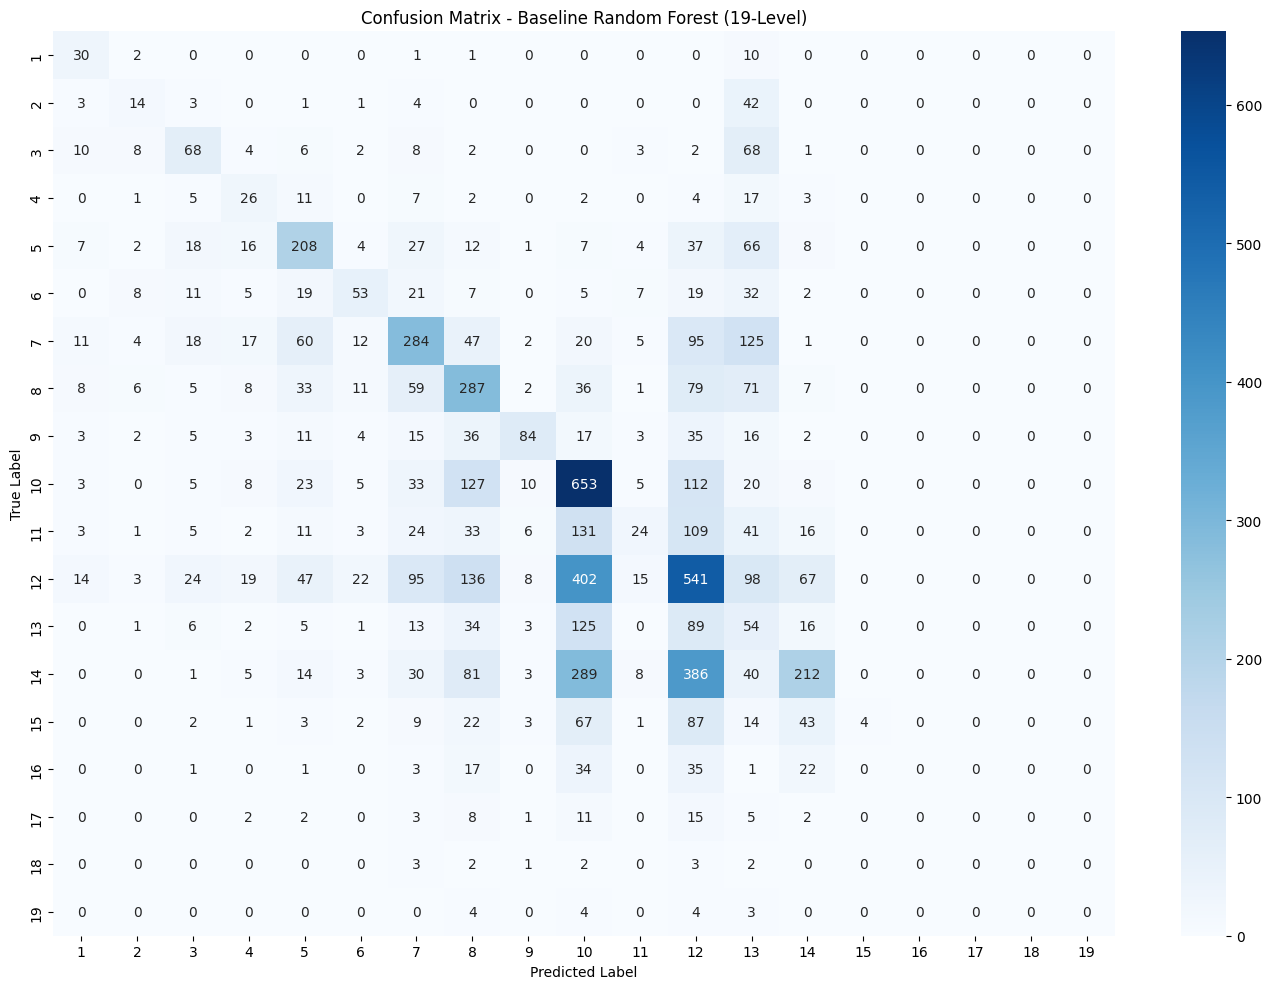

In [ ]:
# Create the baseline Random Forest model using default hyperparameters
rf_baseline_19 = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

print(rf_baseline_19.get_params())

# Train the baseline model
rf_baseline_19.fit(
    rf_X_train_tfidf,
    rf_y_train_19
)

# Generate predictions on the development set
rf_baseline_19_dev_pred = rf_baseline_19.predict(
    rf_X_dev_tfidf
)

# Evaluate the baseline model
evaluate_rf_model(
    rf_y_dev_19,
    rf_baseline_19_dev_pred,
    "Baseline Random Forest (19-Level) - Dev Set",
    level="19-Level", model_name="Baseline"
)

# Plot the confusion matrix
plot_confusion_matrix(
    rf_y_dev_19,
    rf_baseline_19_dev_pred,
    labels=list(range(1, 20)),
    title="Confusion Matrix - Baseline Random Forest (19-Level)"
)

### 4.2 Random Forest Baseline Findings (19-Level)

| Metric | Value |
|---|---|
| Accuracy | 0.3477 |
| Adjacent Accuracy (±1) | 0.4606 |
| Quadratic Weighted Kappa (QWK) | 0.3941 |
| Macro F1-score | 0.2495 |
| Weighted Precision / Recall | 0.3954 / 0.3477 |
| MAE / RMSE | 2.3696 / 3.5434 |
| R² | −0.1045 |

With default hyperparameters, the baseline Random Forest correctly classifies about 35% of the development sentences, and fewer than half (46%) of its predictions fall within one level of the true label. The QWK of 0.3941 indicates only fair agreement with the gold labels, and the negative R² shows that the predicted levels explain less variance than simply predicting the mean level.

**Levels handled relatively well.** The best F1-scores are obtained for level 5 (0.48), level 9 (0.47), level 10 (0.46) and level 1 (0.44). Level 1 has a high recall (0.68), and level 9 has a high precision (0.68). Level 10 has a recall of 0.65, but this is partly because the model over-predicts it.

**Levels the model fails on.** The model never predicts levels 16–19 (F1 = 0.00) and predicts level 15 only 4 times (recall 0.02). Levels 11 (recall 0.06) and 13 (F1 0.10) are also almost never recognized. These are low-frequency classes: levels 16–19 together contain only 191 of the 7,310 development sentences.

**Confusion matrix.** Errors are concentrated in the upper-middle range. Predictions collapse into levels 10 and 12, the two largest classes (1,012 and 1,491 sentences). For example, 386 level-14 sentences are predicted as level 12 and 289 as level 10, and 402 level-12 sentences are predicted as level 10. Every true level from 15 to 19 is pushed down into levels 8–14. This pattern shows a strong bias toward the majority classes, caused by the class imbalance in the training data.

### 4.3 Random Forest Hyperparameter Tuning (19-Level)

**Hyperparameters and Search Space**

The search tunes three Random Forest hyperparameters. All other settings keep their scikit-learn defaults, including `max_features="sqrt"`, `criterion="gini"` and `bootstrap=True`.

- **`n_estimators` (number of trees):** More trees reduce variance, but the improvement diminishes as trees are added (Oshiro et al., 2012). Probst and Boulesteix (2018) argue that the number of trees is not a parameter to be tuned in the usual sense and should simply be set sufficiently high. The values `100` (default), `200` and `300` are tested.

- **`min_samples_split`:** The minimum number of samples required to split an internal node, a form of regularization. The values `2` (default) and `5` are tested.


- **`max_depth`:** The maximum depth of each tree. Fully grown trees (`None`) are the standard Random Forest setting (Breiman, 2001). The shallow values `2` and `5` are included to test whether strongly limiting tree depth acts as useful regularization on the high-dimensional TF-IDF features.

This gives 3 × 2  × 3 = **18 configurations**. A predefined split preserves the original training and development sets. QWK on the development set is used to select the best configuration (see Section 3.4).


**References**

- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Probst, P., Wright, M. N., & Boulesteix, A.-L. (2019). Hyperparameters and tuning strategies for random forest. *WIREs Data Mining and Knowledge Discovery, 9*(3), e1301. https://doi.org/10.1002/widm.1301
- Probst, P., & Boulesteix, A.-L. (2018). To tune or not to tune the number of trees in random forest. *Journal of Machine Learning Research, 18*(181), 1–18.
- Oshiro, T. M., Perez, P. S., & Baranauskas, J. A. (2012). How many trees in a random forest? In *Machine Learning and Data Mining in Pattern Recognition (MLDM 2012)*, LNCS 7376, 154–168. Springer.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.


In [ ]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "min_samples_split": [2, 5],
    "max_depth" :[None, 2, 5],
}

rf_best_params_19, rf_grid_results_19 = run_rf_grid_search(
    param_grid,
    rf_X_train_tfidf, rf_y_train_19,
    rf_X_dev_tfidf, rf_y_dev_19,
    name="rf_grid_19"
)

print("\nBest Parameters:", rf_best_params_19)
print(f"Best Development QWK: {rf_grid_results_19.loc[0, 'dev_qwk']:.4f}")
display(rf_grid_results_19)

18 configurations | 0 already completed
[1/18] {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100} -> dev QWK 0.3941 | accuracy 0.3477 | 43.1 min
[2/18] {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200} -> dev QWK 0.3916 | accuracy 0.3482 | 89.4 min
[3/18] {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 300} -> dev QWK 0.3928 | accuracy 0.3477 | 133.1 min
[4/18] {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100} -> dev QWK 0.4364 | accuracy 0.3625 | 26.4 min
[5/18] {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200} -> dev QWK 0.4289 | accuracy 0.3661 | 53.3 min
[6/18] {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 300} -> dev QWK 0.4392 | accuracy 0.3637 | 80.7 min
[7/18] {'max_depth': 2, 'min_samples_split': 2, 'n_estimators': 100} -> dev QWK 0.0000 | accuracy 0.2040 | 0.0 min
[8/18] {'max_depth': 2, 'min_samples_split': 2, 'n_estimators': 200} -> dev QWK 0.0000 | accuracy 0.2040 | 0.0 min
[9/18] {'max_de

,max_depth,min_samples_split,n_estimators,dev_accuracy,dev_qwk,minutes
0,None,5,300,0.363748,0.439154,80.7
1,None,5,100,0.362517,0.436410,26.4
2,None,5,200,0.366074,0.428861,53.3
3,None,2,100,0.347743,0.394098,43.1
4,None,2,300,0.347743,0.392809,133.1
5,None,2,200,0.348153,0.391641,89.4
6,2,2,100,0.203967,0.000000,0.0
7,2,2,200,0.203967,0.000000,0.0
8,2,2,300,0.203967,0.000000,0.0
9,2,5,100,0.203967,0.000000,0.0


### 4.4 Tuned Random Forest — Balanced (19-Level)

The best hyperparameters selected by the grid search are used to train a Random Forest with `class_weight="balanced"`.

Class weighting gives more importance to less frequent readability levels, based on their frequencies in the training data. The model is trained on the training set and evaluated on the development set.


Tuned Random Forest (19-Level) - Balanced - Dev Set
Accuracy:                      0.3434
Adjacent Accuracy (±1):        0.4473
Quadratic Weighted Kappa:      0.4830
Macro F1-score:                0.2365
Weighted Precision:            0.3825
Weighted Recall:               0.3434
Mean Absolute Error (MAE):     2.4769
Root Mean Squared Error:       3.7623
R² Score:                      -0.2452

Classification Report:

              precision    recall  f1-score   support

           1       0.06      0.91      0.11        44
           2       0.25      0.21      0.23        68
           3       0.34      0.38      0.36       182
           4       0.23      0.36      0.28        78
           5       0.50      0.49      0.50       417
           6       0.41      0.32      0.36       189
           7       0.41      0.39      0.40       701
           8       0.34      0.46      0.39       613
           9       0.60      0.36      0.45       236
          10       0.36      0.61      

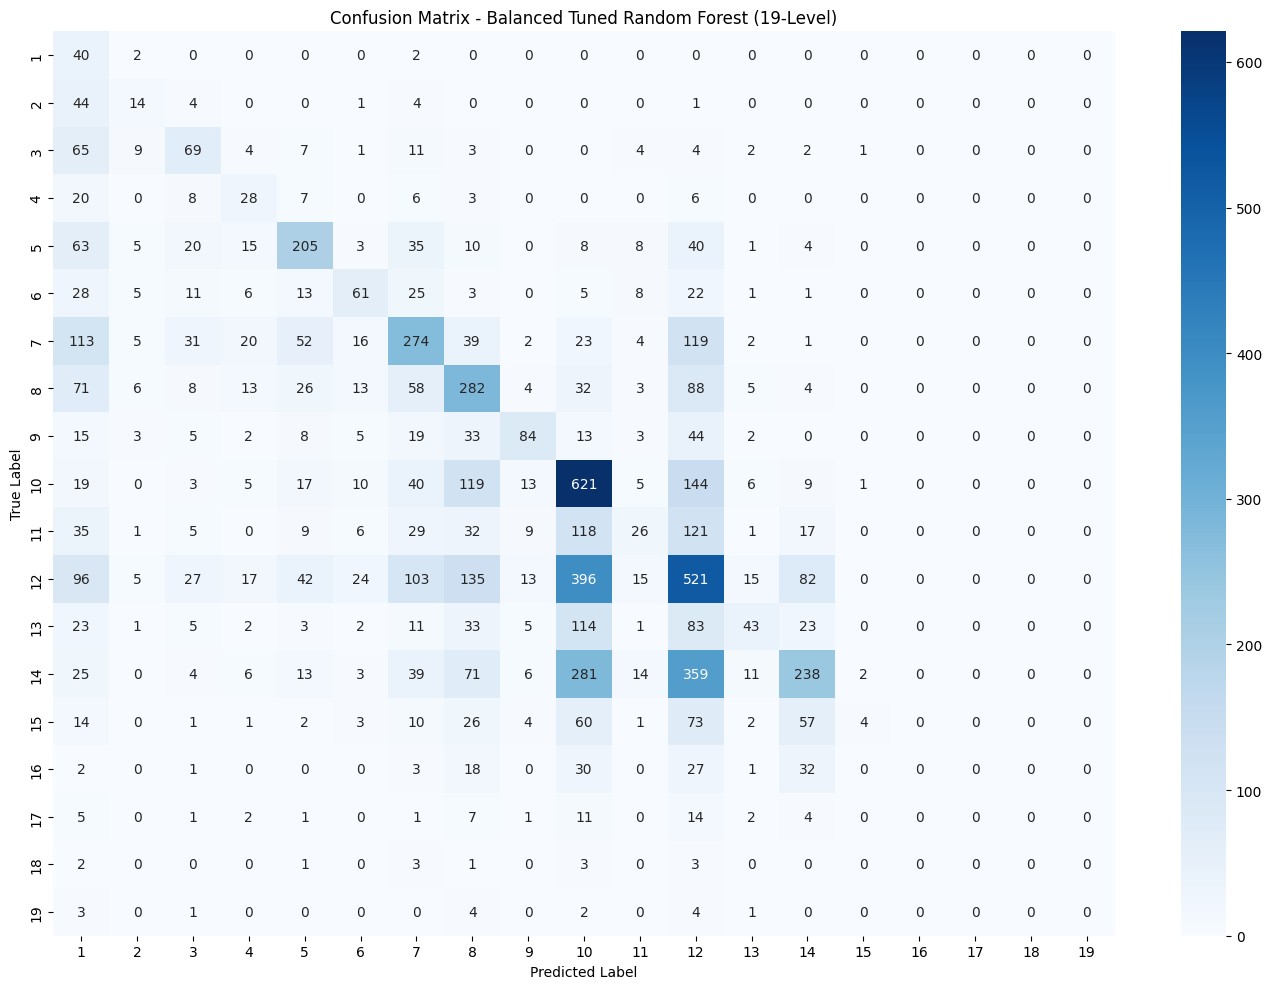

In [ ]:
rf_tuned_19_balanced = RandomForestClassifier(
    **rf_best_params_19,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_tuned_19_balanced.fit(
    rf_X_train_tfidf,
    rf_y_train_19
)

rf_tuned_19_balanced_dev_pred = rf_tuned_19_balanced.predict(
    rf_X_dev_tfidf
)

evaluate_rf_model(
    rf_y_dev_19,
    rf_tuned_19_balanced_dev_pred,
    "Tuned Random Forest (19-Level) - Balanced - Dev Set",
    level="19-Level", model_name="Tuned - Balanced"
)

plot_confusion_matrix(
    rf_y_dev_19,
    rf_tuned_19_balanced_dev_pred,
    labels=list(range(1, 20)),
    title="Confusion Matrix - Balanced Tuned Random Forest (19-Level)"
)

### 4.5 Tuned Random Forest — No Class Weighting (19-Level)

The same selected hyperparameters are used to train a Random Forest with `class_weight=None`.

This configuration allows a direct comparison with the balanced model while keeping the selected hyperparameters unchanged.


Tuned Random Forest (19-Level) - No Class Weighting - Dev Set
Accuracy:                      0.3637
Adjacent Accuracy (±1):        0.4744
Quadratic Weighted Kappa:      0.4392
Macro F1-score:                0.2679
Weighted Precision:            0.4041
Weighted Recall:               0.3637
Mean Absolute Error (MAE):     2.2349
Root Mean Squared Error:       3.3706
R² Score:                      0.0006

Classification Report:

              precision    recall  f1-score   support

           1       0.59      0.68      0.63        44
           2       0.29      0.22      0.25        68
           3       0.36      0.39      0.38       182
           4       0.22      0.29      0.25        78
           5       0.50      0.51      0.51       417
           6       0.47      0.30      0.36       189
           7       0.45      0.43      0.44       701
           8       0.35      0.46      0.40       613
           9       0.69      0.35      0.47       236
          10       0.36      0

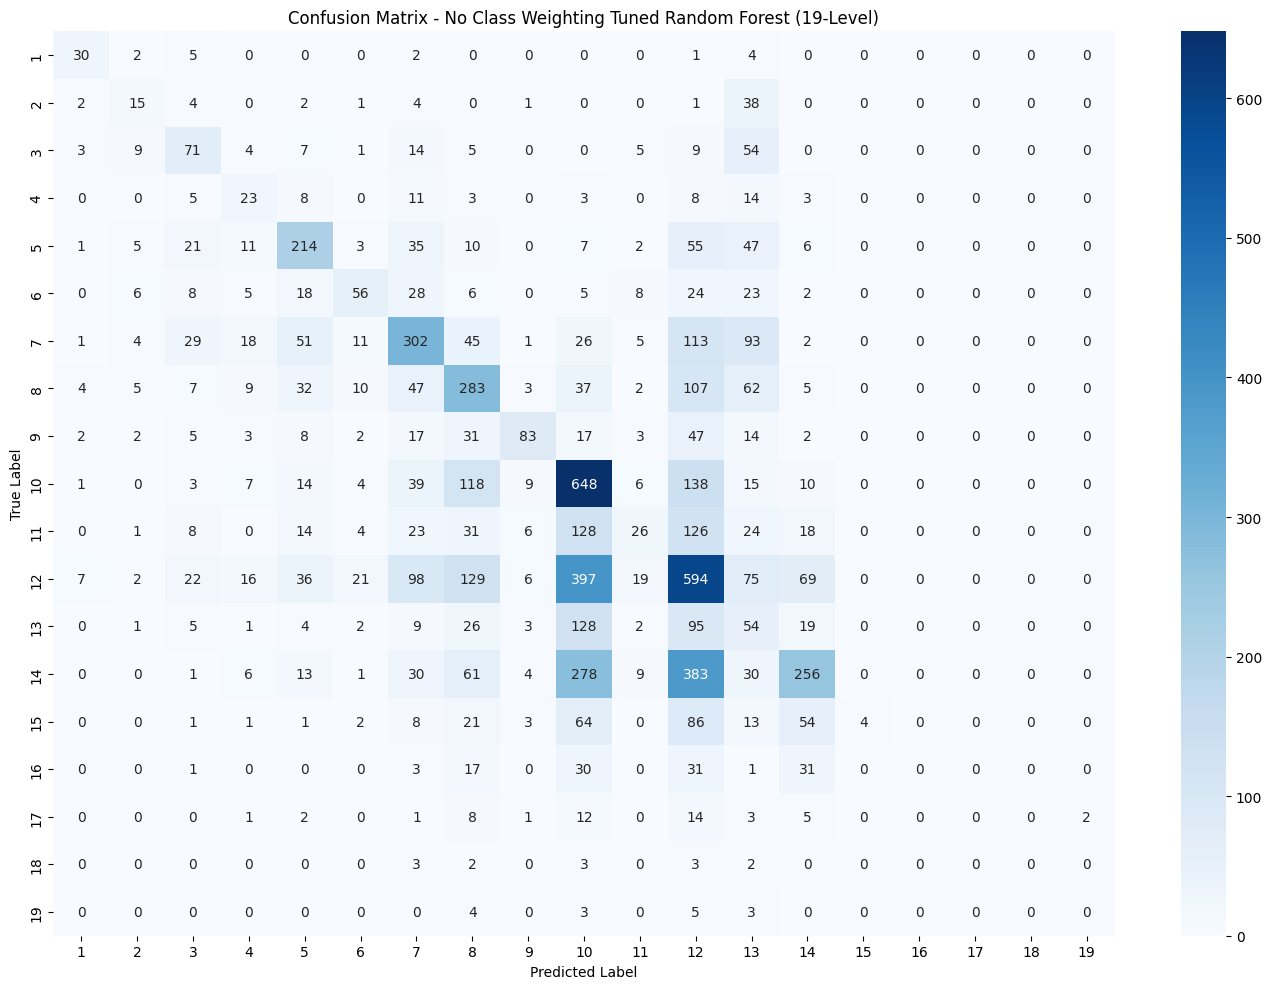

In [ ]:
rf_tuned_19_none = RandomForestClassifier(
    **rf_best_params_19,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

rf_tuned_19_none.fit(
    rf_X_train_tfidf,
    rf_y_train_19
)

rf_tuned_19_none_dev_pred = rf_tuned_19_none.predict(
    rf_X_dev_tfidf
)

evaluate_rf_model(
    rf_y_dev_19,
    rf_tuned_19_none_dev_pred,
    "Tuned Random Forest (19-Level) - No Class Weighting - Dev Set",
    level="19-Level", model_name="Tuned - None"
)

plot_confusion_matrix(
    rf_y_dev_19,
    rf_tuned_19_none_dev_pred,
    labels=list(range(1, 20)),
    title="Confusion Matrix - No Class Weighting Tuned Random Forest (19-Level)"
)

### 4.6 Tuned Random Forest Findings (19-Level)

**Selected hyperparameters.** The grid search selected `n_estimators=300`, `min_samples_split=5` and `max_depth=None`, with a development QWK of **0.4392**, compared with 0.3941 for the baseline.

**What the grid search shows.**

- **`min_samples_split` is the most influential parameter.** Increasing it from 2 to 5 raised the development QWK from about 0.39 to 0.43–0.44, and also reduced training time (for example, 43.1 → 26.4 minutes with 100 trees).
- **`n_estimators` has a small effect.** With the same `min_samples_split`, changing the number of trees from 100 to 300 changed the QWK by less than 0.01.
- **Shallow trees fail completely.** With `max_depth=2` or `5`, every configuration achieved an Accuracy of 0.2040 and a QWK of 0.0000. This equals the share of level 12 in the development set (1,491 / 7,310), meaning that the model predicted the majority class for every sentence.

**Effect of class weighting.**

| Model | Accuracy | Adj. Acc. (±1) | QWK | Macro F1 | MAE | RMSE | R² |
|---|---|---|---|---|---|---|---|
| Baseline | 0.3477 | 0.4606 | 0.3941 | 0.2495 | 2.3696 | 3.5434 | -0.1045 |
| Tuned – Balanced | 0.3434 | 0.4473 | **0.4830** | 0.2365 | 2.4769 | 3.7623 | -0.2452 |
| Tuned – None | **0.3637** | **0.4744** | 0.4392 | **0.2679** | **2.2349** | **3.3706** | **0.0006** |

- **Tuned – None** improved on the baseline in every metric and achieved the best Accuracy, Adjacent Accuracy, Macro F1, MAE, RMSE and R².
- **Tuned – Balanced** achieved the highest QWK (0.4830), but lower Accuracy and larger errors (MAE 2.4769). Class weighting made the model predict level 1 much more often: its recall rose to 0.91, but its precision dropped to 0.06. The precision of level 13 increased from 0.09 to 0.45.
- Both tuned models still never predicted levels 16–19 correctly, and level 15 had a recall of only 0.02. These levels contain very few sentences (191 of 7,310 for levels 16–19).

**Retained configuration (19-level): Tuned – Balanced**, because it achieved the highest development QWK, which is the selection metric. However, the unweighted model is better on all other metrics, so the choice depends on the evaluation metric.


## **5. Random Forest (5-Level)**

### 5.1 Random Forest Baseline (5-Level)

A baseline Random Forest is trained using the default hyperparameters to establish a reference point for the 5-level Arabic readability classification task.

The model uses TF-IDF features extracted from the `Word` text representation. Its performance is evaluated on the development set using classification and ordinal metrics, including Accuracy, Adjacent Accuracy (±1), Quadratic Weighted Kappa (QWK), Macro F1-score, MAE, and RMSE.

The baseline results will serve as a reference for subsequent hyperparameter tuning experiments.

{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Baseline Random Forest (5-Level) - Dev Set
Accuracy:                      0.4718
Adjacent Accuracy (±1):        0.7594
Quadratic Weighted Kappa:      0.2946
Macro F1-score:                0.3330
Weighted Precision:            0.4834
Weighted Recall:               0.4718
Mean Absolute Error (MAE):     0.8055
Root Mean Squared Error:       1.1994
R² Score:                      -0.1708

Classification Report:

              precision    recall  f1-score   support

           1       0.59      0.68      0.63      1679
           2       0.44      0.77      0.56      2270
           3  

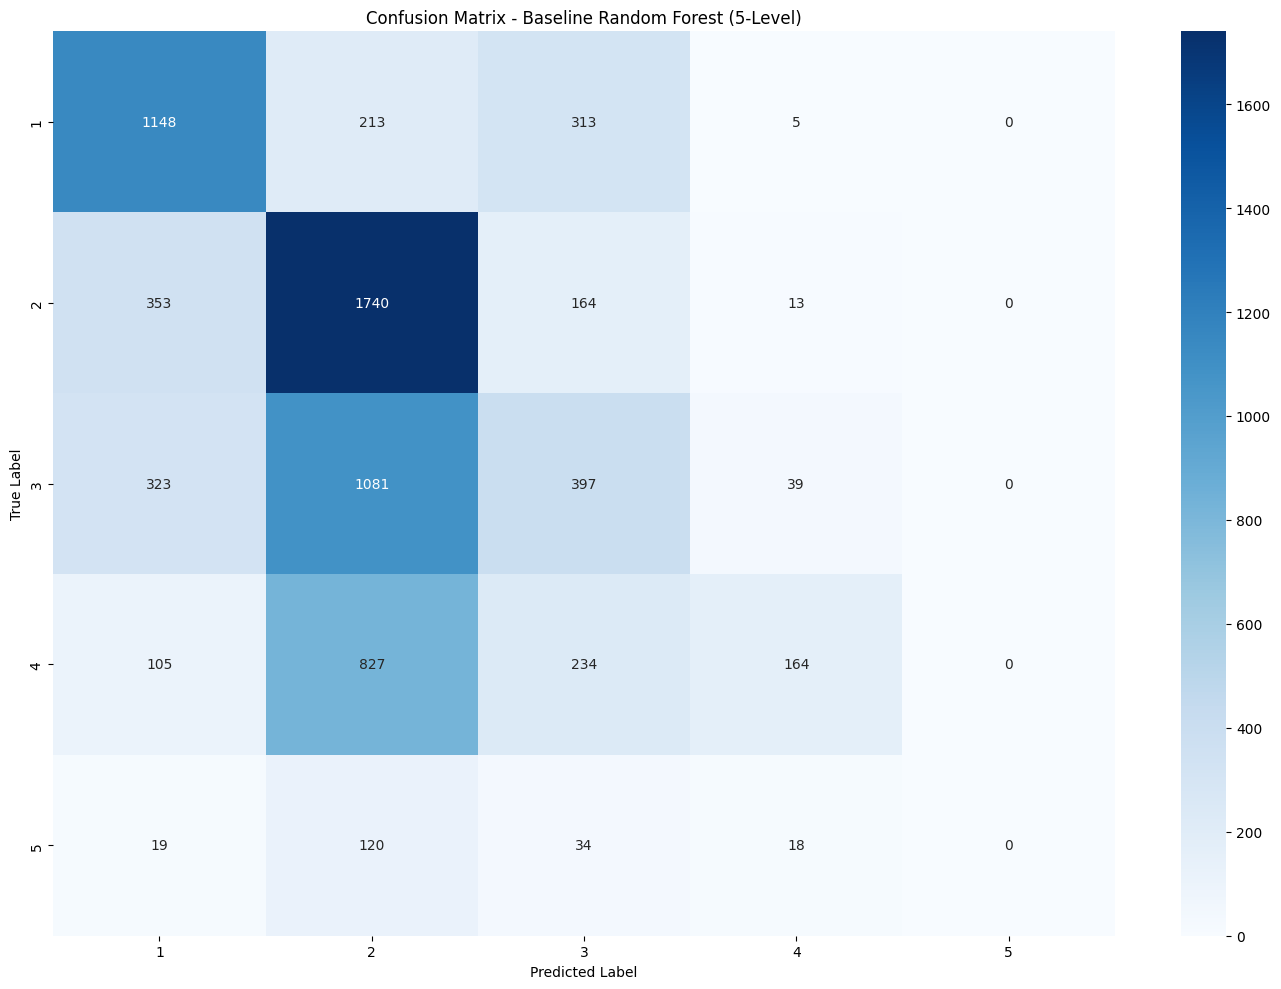

In [ ]:
# Create the baseline Random Forest model using default hyperparameters
rf_baseline_5 = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

print(rf_baseline_5.get_params())

# Train the baseline model
rf_baseline_5.fit(
    rf_X_train_tfidf,
    rf_y_train_5
)

# Generate predictions on the development set
rf_baseline_5_dev_pred = rf_baseline_5.predict(
    rf_X_dev_tfidf
)

# Evaluate the baseline model
evaluate_rf_model(
    rf_y_dev_5,
    rf_baseline_5_dev_pred,
    "Baseline Random Forest (5-Level) - Dev Set",
    level="5-Level", model_name="Baseline"
)

# Plot the confusion matrix
plot_confusion_matrix(
    rf_y_dev_5,
    rf_baseline_5_dev_pred,
    labels=sorted(rf_y_train_5.unique()),
    title="Confusion Matrix - Baseline Random Forest (5-Level)"
)

### 5.2 Random Forest Baseline Findings (5-Level)

| Metric | Value |
|---|---|
| Accuracy | 0.4718 |
| Adjacent Accuracy (±1) | 0.7594 |
| Quadratic Weighted Kappa (QWK) | 0.2946 |
| Macro F1-score | 0.3330 |
| Weighted Precision / Recall | 0.4834 / 0.4718 |
| MAE / RMSE | 0.8055 / 1.1994 |
| R² | −0.1708 |

On the 5-level task, the baseline classifies 47% of the development sentences correctly, and 76% of its predictions fall within one level of the truth. The QWK, however, is low (0.2946), which shows that the predictions do not follow the ordinal structure of the levels well.

**Levels handled relatively well.** Level 1 (F1 0.63, recall 0.68) and level 2 (F1 0.56, recall 0.77) are recognized best. Level 2 is the largest class (2,270 sentences).

**Levels the model fails on.** Level 3 (recall 0.22) and level 4 (recall 0.12) are poorly recognized, and level 5 is never predicted (F1 0.00, 191 sentences).

**Confusion matrix.** The model is strongly biased toward level 2. It assigns level 2 to 1,081 of the 1,840 level-3 sentences, 827 of the 1,330 level-4 sentences, and 120 of the 191 level-5 sentences. Because higher levels are pulled down toward level 2, the predicted levels compress toward the lower end of the scale. This explains the low QWK despite the reasonable Adjacent Accuracy.

### 5.3 Random Forest Hyperparameter Tuning (5-Level)

**Hyperparameters and Search Space**

The same search space as the 19-level task (Section 4.3) is used, with the same references:

- `n_estimators`: `100`, `200`, `300`
- `min_samples_split`: `2`, `5`
- `max_depth`: `None`, `2`, `5`

This gives **18 configurations**. All other hyperparameters keep their scikit-learn defaults (`max_features="sqrt"`). Each configuration is trained on the training set and scored on the development set, and the configuration with the highest development QWK is selected.


In [ ]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "min_samples_split": [2, 5],
    "max_depth" :[None, 2, 5],
}

rf_best_params_5, rf_grid_results_5 = run_rf_grid_search(
    param_grid,
    rf_X_train_tfidf, rf_y_train_5,
    rf_X_dev_tfidf, rf_y_dev_5,
    name="rf_grid_5"
)

print("\nBest Parameters:", rf_best_params_5)
print(f"Best Development QWK: {rf_grid_results_5.loc[0, 'dev_qwk']:.4f}")
display(rf_grid_results_5)

18 configurations | 4 already completed
[5/18] {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200} -> dev QWK 0.3902 | accuracy 0.5097 | 44.9 min
[6/18] {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 300} -> dev QWK 0.3853 | accuracy 0.5048 | 66.3 min
[7/18] {'max_depth': 2, 'min_samples_split': 2, 'n_estimators': 100} -> dev QWK 0.0000 | accuracy 0.3105 | 0.0 min
[8/18] {'max_depth': 2, 'min_samples_split': 2, 'n_estimators': 200} -> dev QWK 0.0000 | accuracy 0.3105 | 0.0 min
[9/18] {'max_depth': 2, 'min_samples_split': 2, 'n_estimators': 300} -> dev QWK 0.0000 | accuracy 0.3105 | 0.0 min
[10/18] {'max_depth': 2, 'min_samples_split': 5, 'n_estimators': 100} -> dev QWK 0.0000 | accuracy 0.3105 | 0.0 min
[11/18] {'max_depth': 2, 'min_samples_split': 5, 'n_estimators': 200} -> dev QWK 0.0000 | accuracy 0.3105 | 0.0 min
[12/18] {'max_depth': 2, 'min_samples_split': 5, 'n_estimators': 300} -> dev QWK 0.0000 | accuracy 0.3105 | 0.1 min
[13/18] {'max_depth': 5, 'min

,max_depth,min_samples_split,n_estimators,dev_accuracy,dev_qwk,minutes
0,NaN,5,200,0.509713,0.390171,44.9
1,NaN,5,100,0.507661,0.387482,13.3
2,None,5,300,0.504788,0.385349,66.3
3,NaN,2,100,0.471819,0.294634,37.0
4,NaN,2,300,0.470862,0.292050,57.7
5,NaN,2,200,0.472640,0.291048,76.0
6,2,2,100,0.310534,0.000000,0.0
7,2,2,200,0.310534,0.000000,0.0
8,2,2,300,0.310534,0.000000,0.0
9,2,5,100,0.310534,0.000000,0.0


### 5.4 Tuned Random Forest — Balanced (5-Level)

The best hyperparameters selected by the grid search are used to train a balanced Random Forest for the 5-level classification task.

Class weighting is applied to examine whether accounting for differences in class frequencies improves performance.


Tuned Random Forest (5-Level) - Balanced - Dev Set
Accuracy:                      0.5059
Adjacent Accuracy (±1):        0.7858
Quadratic Weighted Kappa:      0.3851
Macro F1-score:                0.3585
Weighted Precision:            0.5455
Weighted Recall:               0.5059
Mean Absolute Error (MAE):     0.7543
Root Mean Squared Error:       1.1731
R² Score:                      -0.1200

Classification Report:

              precision    recall  f1-score   support

           1       0.57      0.87      0.68      1679
           2       0.45      0.75      0.56      2270
           3       0.52      0.16      0.25      1840
           4       0.66      0.18      0.29      1330
           5       1.00      0.01      0.01       191

    accuracy                           0.51      7310
   macro avg       0.64      0.39      0.36      7310
weighted avg       0.55      0.51      0.45      7310



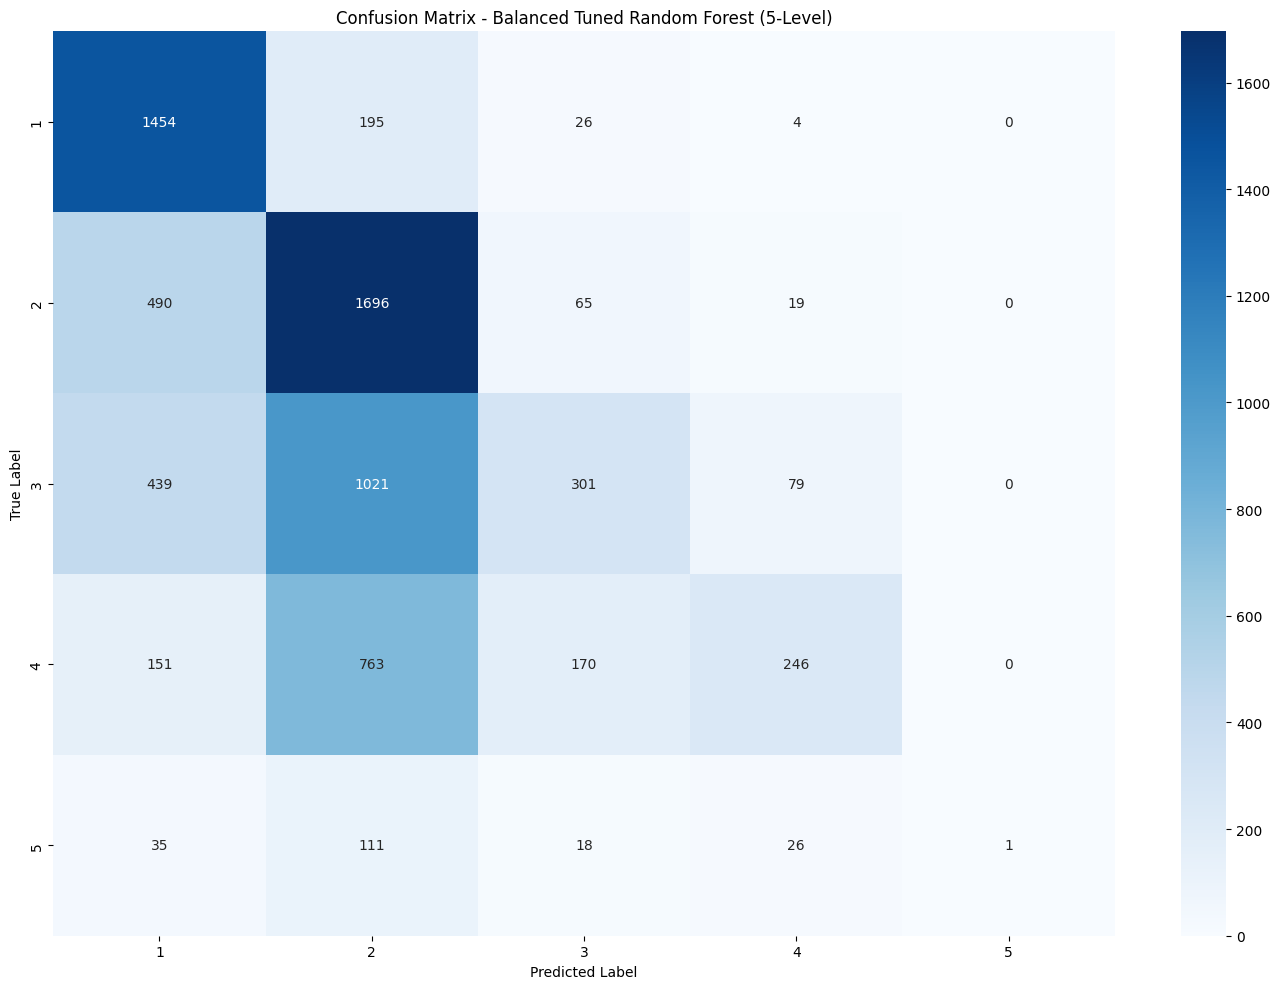

In [ ]:
rf_tuned_5_balanced = RandomForestClassifier(
    **rf_best_params_5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_tuned_5_balanced.fit(
    rf_X_train_tfidf,
    rf_y_train_5
)

rf_tuned_5_balanced_dev_pred = rf_tuned_5_balanced.predict(
    rf_X_dev_tfidf
)

evaluate_rf_model(
    rf_y_dev_5,
    rf_tuned_5_balanced_dev_pred,
    "Tuned Random Forest (5-Level) - Balanced - Dev Set",
    level="5-Level", model_name="Tuned - Balanced"
)

plot_confusion_matrix(
    rf_y_dev_5,
    rf_tuned_5_balanced_dev_pred,
    labels=sorted(rf_y_train_5.unique()),
    title="Confusion Matrix - Balanced Tuned Random Forest (5-Level)"
)

### 5.5 Tuned Random Forest — No Class Weighting (5-Level)

The selected hyperparameters are used to train an unweighted Random Forest for the 5-level classification task.

This configuration is compared with the balanced model to evaluate the effect of class weighting.


Tuned Random Forest (5-Level) - No Class Weighting - Dev Set
Accuracy:                      0.5097
Adjacent Accuracy (±1):        0.7927
Quadratic Weighted Kappa:      0.3902
Macro F1-score:                0.3618
Weighted Precision:            0.5596
Weighted Recall:               0.5097
Mean Absolute Error (MAE):     0.7373
Root Mean Squared Error:       1.1478
R² Score:                      -0.0721

Classification Report:

              precision    recall  f1-score   support

           1       0.60      0.83      0.70      1679
           2       0.44      0.79      0.57      2270
           3       0.52      0.17      0.26      1840
           4       0.70      0.16      0.27      1330
           5       1.00      0.01      0.02       191

    accuracy                           0.51      7310
   macro avg       0.65      0.39      0.36      7310
weighted avg       0.56      0.51      0.45      7310



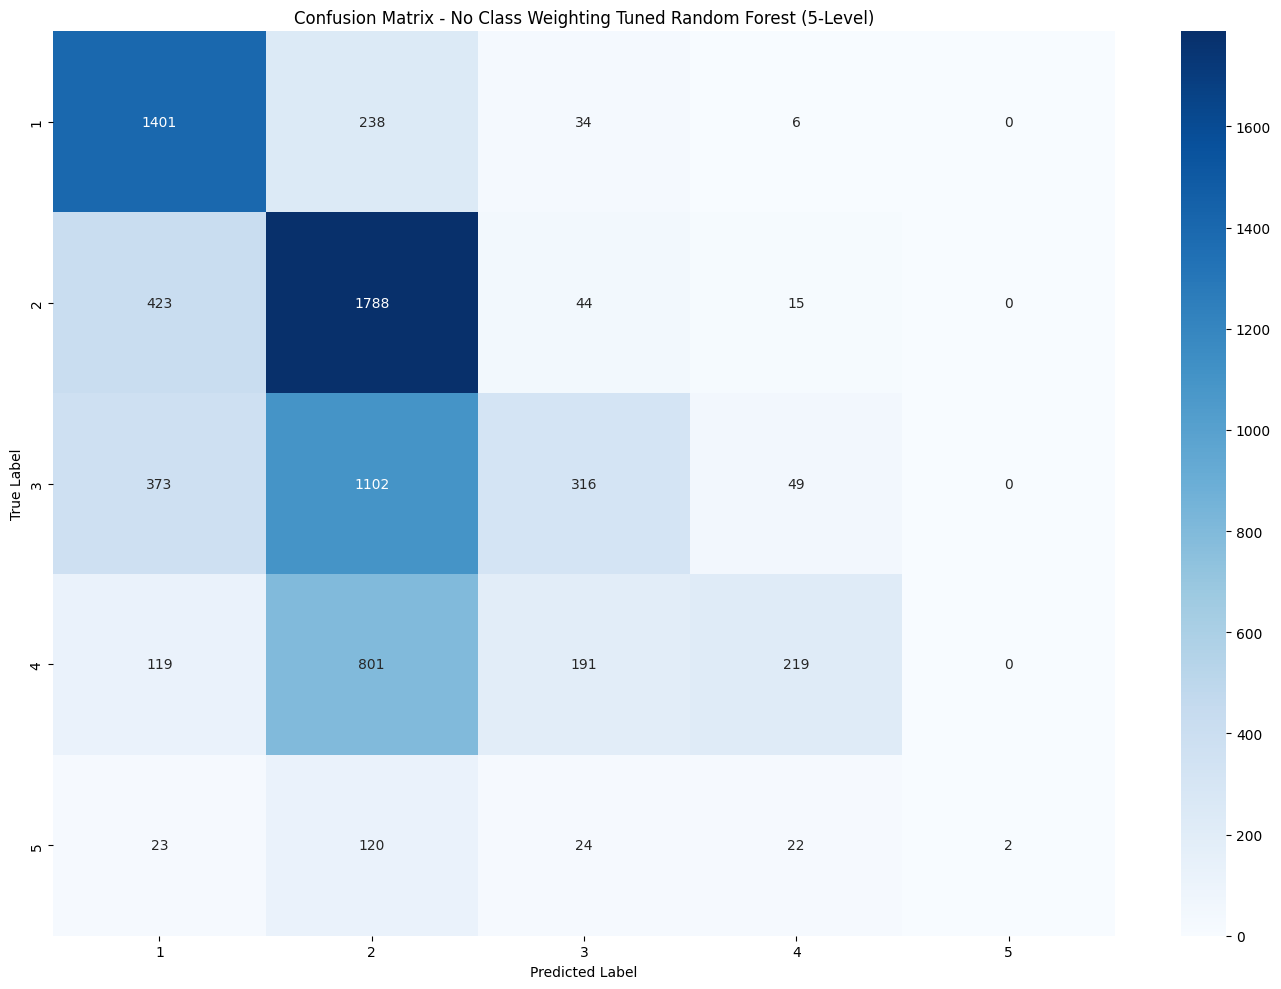

In [ ]:
rf_tuned_5_none = RandomForestClassifier(
    **rf_best_params_5,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

rf_tuned_5_none.fit(
    rf_X_train_tfidf,
    rf_y_train_5
)

rf_tuned_5_none_dev_pred = rf_tuned_5_none.predict(
    rf_X_dev_tfidf
)

evaluate_rf_model(
    rf_y_dev_5,
    rf_tuned_5_none_dev_pred,
    "Tuned Random Forest (5-Level) - No Class Weighting - Dev Set",
    level="5-Level", model_name="Tuned - None"
)

plot_confusion_matrix(
    rf_y_dev_5,
    rf_tuned_5_none_dev_pred,
    labels=sorted(rf_y_train_5.unique()),
    title="Confusion Matrix - No Class Weighting Tuned Random Forest (5-Level)"
)

### 5.6 Tuned Random Forest Findings (5-Level)

**Selected hyperparameters.** The grid search selected `n_estimators=200`, `min_samples_split=5` and `max_depth=None`, with a development QWK of **0.3902**, compared with 0.2946 for the baseline.

**What the grid search shows.** The pattern matches the 19-level task:

- Increasing `min_samples_split` from 2 to 5 gave the largest gain, raising the development QWK from about 0.29 to 0.39.
- The number of trees had a small effect: the three configurations with `min_samples_split=5` lie between 0.3853 and 0.3902.
- With `max_depth=2` or `5`, every configuration achieved an Accuracy of 0.3105 and a QWK of 0.0000. This equals the share of level 2 in the development set (2,270 / 7,310), so the model again predicted only the majority class.

**Effect of class weighting.**

| Model | Accuracy | Adj. Acc. (±1) | QWK | Macro F1 | MAE | RMSE | R² |
|---|---|---|---|---|---|---|---|
| Baseline | 0.4718 | 0.7594 | 0.2946 | 0.3330 | 0.8055 | 1.1994 | -0.1708 |
| Tuned – Balanced | 0.5059 | 0.7858 | 0.3851 | 0.3585 | 0.7543 | 1.1731 | -0.1200 |
| Tuned – None | **0.5097** | **0.7927** | **0.3902** | **0.3618** | **0.7373** | **1.1478** | **-0.0721** |

- Both tuned models clearly outperformed the baseline on every metric.
- **Tuned – None** achieved the best result on every metric. Class weighting did not improve the 5-level model: the balanced and unweighted models produced very similar predictions.
- Both models recognized level 1 (recall 0.83–0.87) and level 2 (recall 0.75–0.79) well, but struggled with level 3 (recall 0.16–0.17) and level 4 (recall 0.16–0.18). Level 5 was almost never predicted (recall 0.01).

**Retained configuration (5-level): Tuned – None**, because it achieved the highest development QWK and is also the best on all other metrics.


## **6. Random Forest (4-Level)**

### 6.1 Random Forest Baseline (4-Level)

A baseline Random Forest is trained using the default hyperparameters to establish a reference point for the 4-level Arabic readability classification task.

The model uses TF-IDF features extracted from the `Word` text representation. Its performance is evaluated on the development set using classification and ordinal metrics, including Accuracy, Adjacent Accuracy (±1), Quadratic Weighted Kappa (QWK), Macro F1-score, MAE, and RMSE.

The baseline results will serve as a reference for subsequent hyperparameter tuning experiments.

{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Baseline Random Forest (4-Level) - Dev Set
Accuracy:                      0.4841
Adjacent Accuracy (±1):        0.7714
Quadratic Weighted Kappa:      0.3334
Macro F1-score:                0.4368
Weighted Precision:            0.5265
Weighted Recall:               0.4841
Mean Absolute Error (MAE):     0.7629
Root Mean Squared Error:       1.1375
R² Score:                      -0.1536

Classification Report:

              precision    recall  f1-score   support

           1       0.59      0.69      0.63      1679
           2       0.44      0.76      0.56      2270
           3  

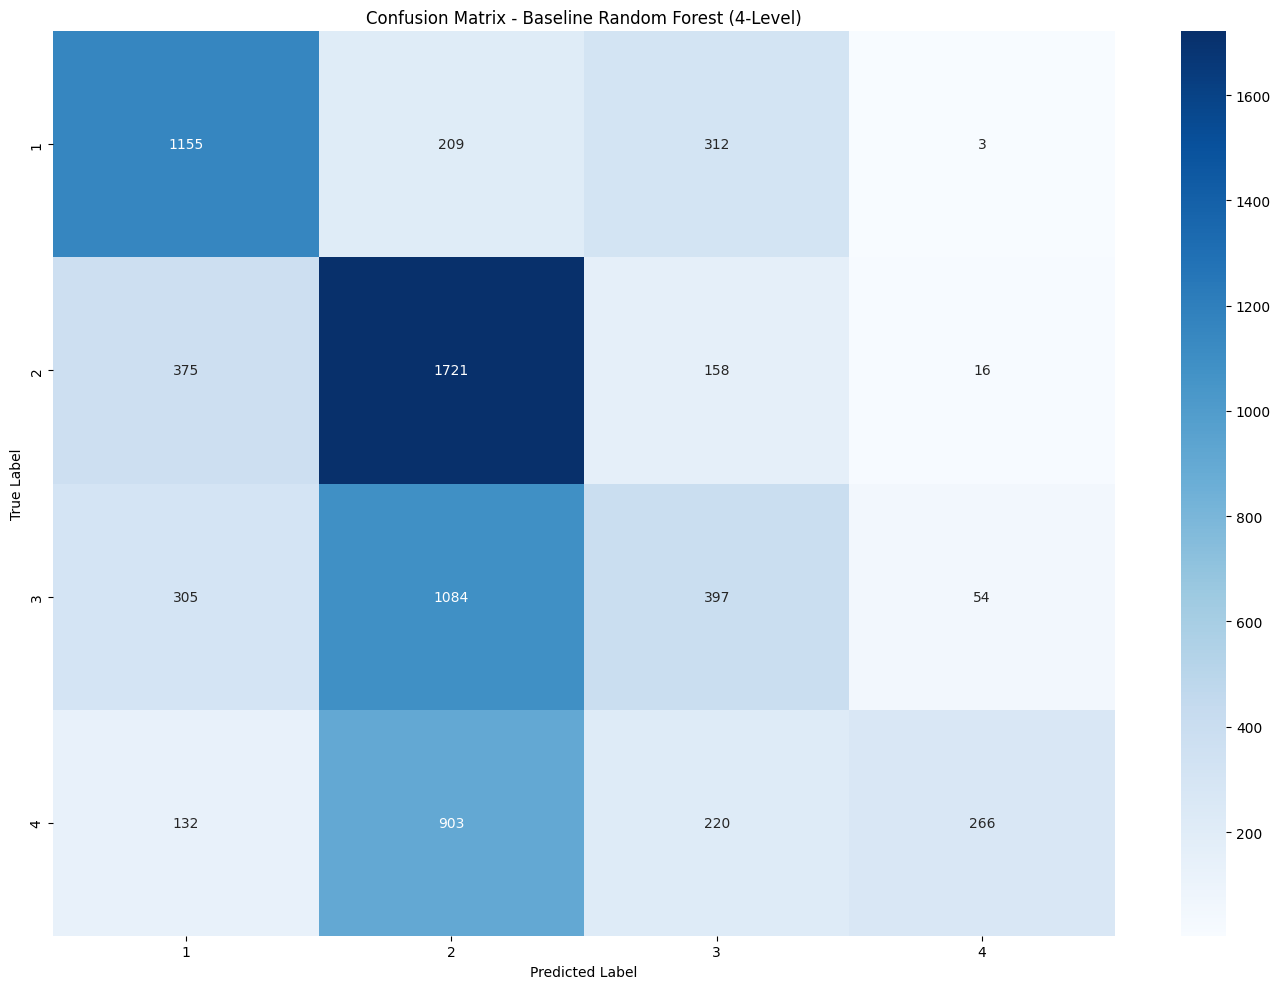

In [ ]:
# Create the baseline Random Forest model using default hyperparameters
rf_baseline_4 = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

print(rf_baseline_4.get_params())

# Train the baseline model
rf_baseline_4.fit(
    rf_X_train_tfidf,
    rf_y_train_4
)

# Generate predictions on the development set
rf_baseline_4_dev_pred = rf_baseline_4.predict(
    rf_X_dev_tfidf
)

# Evaluate the baseline model
evaluate_rf_model(
    rf_y_dev_4,
    rf_baseline_4_dev_pred,
    "Baseline Random Forest (4-Level) - Dev Set",
    level="4-Level", model_name="Baseline"
)

# Plot the confusion matrix
plot_confusion_matrix(
    rf_y_dev_4,
    rf_baseline_4_dev_pred,
    labels=sorted(rf_y_train_4.unique()),
    title="Confusion Matrix - Baseline Random Forest (4-Level)"
)

### 6.2 Random Forest Baseline Findings (4-Level)

| Metric | Value |
|---|---|
| Accuracy | 0.4841 |
| Adjacent Accuracy (±1) | 0.7714 |
| Quadratic Weighted Kappa (QWK) | 0.3334 |
| Macro F1-score | 0.4368 |
| Weighted Precision / Recall | 0.5265 / 0.4841 |
| MAE / RMSE | 0.7629 / 1.1375 |
| R² | −0.1536 |

On the 4-level task, the baseline classified 48% of the development sentences correctly, and 77% of its predictions fall within one level of the true label. The QWK of 0.3334 is higher than that of the 5-level baseline (0.2946), and the Macro F1-score increased from 0.3330 to 0.4368, because the very small level 5 was merged into level 4.

**Levels handled relatively well.** Level 1 (F1 0.63, recall 0.69) and level 2 (F1 0.56, recall 0.76) are recognized best.

**Levels the model struggles with.** Level 3 (recall 0.22) and level 4 (recall 0.17) are poorly recognized. Level 4 has a high precision (0.78) but a very low recall, meaning that the model rarely predicts level 4, and most level-4 sentences are assigned to lower levels. These results establish the baseline for comparison with the tuned models.


### 6.3 Random Forest Hyperparameter Tuning (4-Level)

**Hyperparameters and Search Space**

The same search space as the 19-level task (Section 4.3) is used for the merged 4-level labels, with the same references:

- `n_estimators`: `100`, `200`, `300`
- `min_samples_split`: `2`, `5`
- `max_depth`: `None`, `2`, `5`

This gives **18 configurations**. All other hyperparameters keep their scikit-learn defaults (`max_features="sqrt"`). Each configuration is trained on the training set and scored on the development set, and the configuration with the highest development QWK is selected.

In [ ]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "min_samples_split": [2, 5],
    "max_depth" :[None, 2, 5],
}

rf_best_params_4, rf_grid_results_4 = run_rf_grid_search(
    param_grid,
    rf_X_train_tfidf, rf_y_train_4,
    rf_X_dev_tfidf, rf_y_dev_4,
    name="rf_grid_4"
)

print("\nBest Parameters:", rf_best_params_4)
print(f"Best Development QWK: {rf_grid_results_4.loc[0, 'dev_qwk']:.4f}")
display(rf_grid_results_4)

18 configurations | 5 already completed
[6/18] {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 300} -> dev QWK 0.4236 | accuracy 0.5196 | 95.7 min
[7/18] {'max_depth': 2, 'min_samples_split': 2, 'n_estimators': 100} -> dev QWK 0.0000 | accuracy 0.3105 | 0.0 min
[8/18] {'max_depth': 2, 'min_samples_split': 2, 'n_estimators': 200} -> dev QWK 0.0000 | accuracy 0.3105 | 0.0 min
[9/18] {'max_depth': 2, 'min_samples_split': 2, 'n_estimators': 300} -> dev QWK 0.0000 | accuracy 0.3105 | 0.1 min
[10/18] {'max_depth': 2, 'min_samples_split': 5, 'n_estimators': 100} -> dev QWK 0.0000 | accuracy 0.3105 | 0.0 min
[11/18] {'max_depth': 2, 'min_samples_split': 5, 'n_estimators': 200} -> dev QWK 0.0000 | accuracy 0.3105 | 0.0 min
[12/18] {'max_depth': 2, 'min_samples_split': 5, 'n_estimators': 300} -> dev QWK 0.0000 | accuracy 0.3105 | 0.0 min
[13/18] {'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 100} -> dev QWK 0.0000 | accuracy 0.3105 | 0.0 min
[14/18] {'max_depth': 5, 'min_sa

,max_depth,min_samples_split,n_estimators,dev_accuracy,dev_qwk,minutes
0,None,5,300,0.519562,0.423614,95.7
1,NaN,5,200,0.519425,0.422887,26.4
2,NaN,5,100,0.518194,0.421943,13.5
3,NaN,2,100,0.484131,0.333405,35.2
4,NaN,2,200,0.484405,0.332537,70.9
5,NaN,2,300,0.481532,0.327446,58.7
6,2,2,100,0.310534,0.000000,0.0
7,2,2,200,0.310534,0.000000,0.0
8,2,2,300,0.310534,0.000000,0.1
9,2,5,100,0.310534,0.000000,0.0


### 6.4 Tuned Random Forest — Balanced (4-Level)

The best hyperparameters selected by the grid search are used to train a balanced Random Forest for the 4-level classification task.

The model is evaluated on the development set to examine the effect of class weighting.


Tuned Random Forest (4-Level) - Balanced - Dev Set
Accuracy:                      0.5231
Adjacent Accuracy (±1):        0.7981
Quadratic Weighted Kappa:      0.4310
Macro F1-score:                0.4668
Weighted Precision:            0.5701
Weighted Recall:               0.5231
Mean Absolute Error (MAE):     0.7045
Root Mean Squared Error:       1.1006
R² Score:                      -0.0798

Classification Report:

              precision    recall  f1-score   support

           1       0.57      0.87      0.69      1679
           2       0.46      0.75      0.57      2270
           3       0.55      0.16      0.24      1840
           4       0.76      0.24      0.37      1521

    accuracy                           0.52      7310
   macro avg       0.59      0.51      0.47      7310
weighted avg       0.57      0.52      0.47      7310



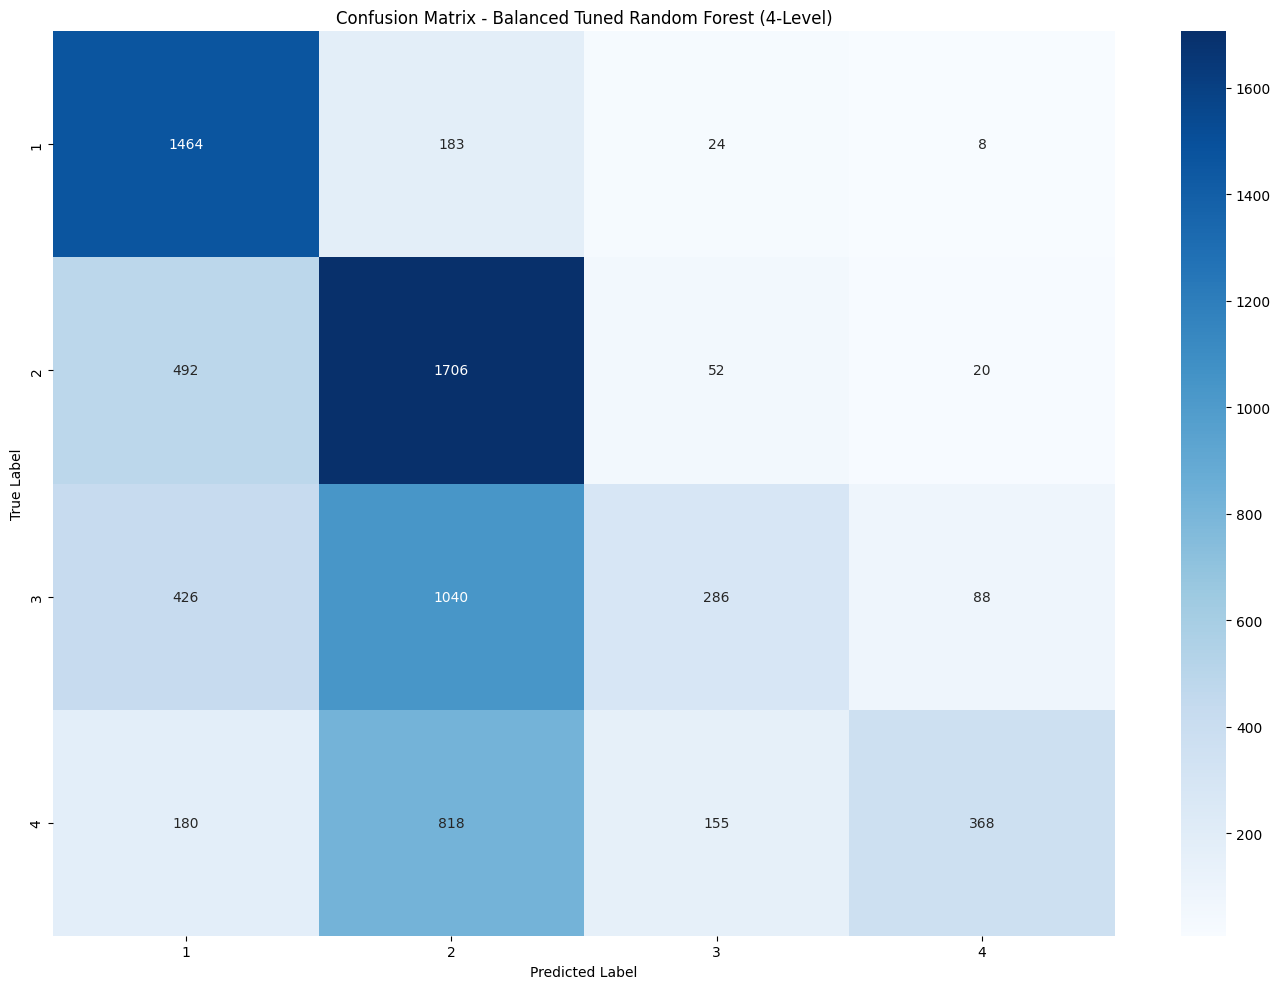

In [ ]:
rf_tuned_4_balanced = RandomForestClassifier(
    **rf_best_params_4,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_tuned_4_balanced.fit(
    rf_X_train_tfidf,
    rf_y_train_4
)

rf_tuned_4_balanced_dev_pred = rf_tuned_4_balanced.predict(
    rf_X_dev_tfidf
)

evaluate_rf_model(
    rf_y_dev_4,
    rf_tuned_4_balanced_dev_pred,
    "Tuned Random Forest (4-Level) - Balanced - Dev Set",
    level="4-Level", model_name="Tuned - Balanced"
)

plot_confusion_matrix(
    rf_y_dev_4,
    rf_tuned_4_balanced_dev_pred,
    labels=sorted(rf_y_train_4.unique()),
    title="Confusion Matrix - Balanced Tuned Random Forest (4-Level)"
)

### 6.5 Tuned Random Forest — No Class Weighting (4-Level)

The selected hyperparameters are used to train an unweighted Random Forest for the 4-level classification task.

This configuration is evaluated on the same development set to compare its performance with the balanced model.


Tuned Random Forest (4-Level) - No Class Weighting - Dev Set
Accuracy:                      0.5196
Adjacent Accuracy (±1):        0.8007
Quadratic Weighted Kappa:      0.4236
Macro F1-score:                0.4611
Weighted Precision:            0.5702
Weighted Recall:               0.5196
Mean Absolute Error (MAE):     0.7008
Root Mean Squared Error:       1.0880
R² Score:                      -0.0553

Classification Report:

              precision    recall  f1-score   support

           1       0.60      0.83      0.69      1679
           2       0.45      0.79      0.57      2270
           3       0.54      0.16      0.25      1840
           4       0.76      0.21      0.33      1521

    accuracy                           0.52      7310
   macro avg       0.59      0.50      0.46      7310
weighted avg       0.57      0.52      0.47      7310



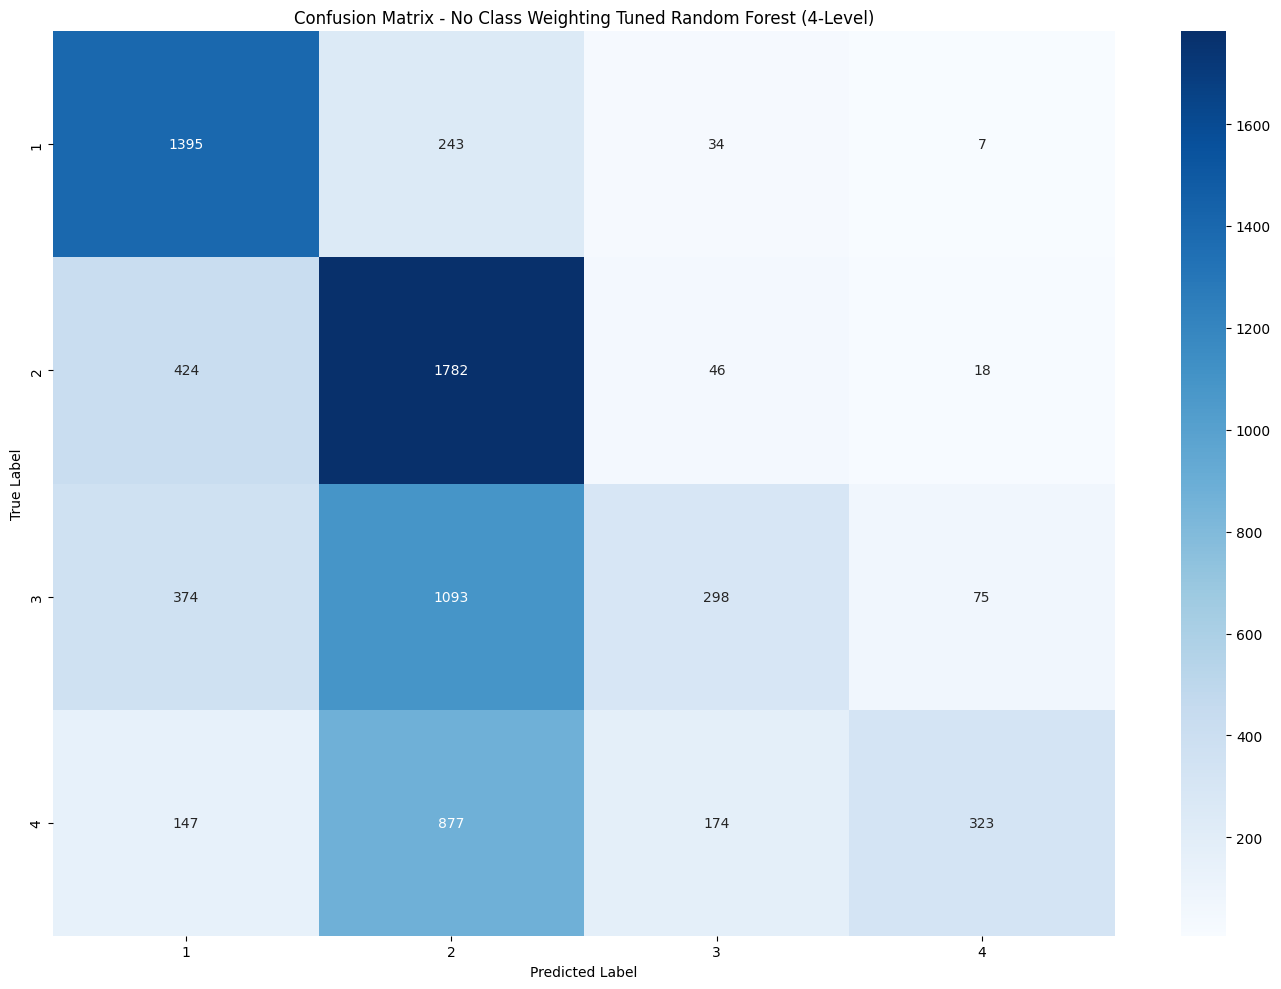

In [ ]:
rf_tuned_4_none = RandomForestClassifier(
    **rf_best_params_4,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

rf_tuned_4_none.fit(
    rf_X_train_tfidf,
    rf_y_train_4
)

rf_tuned_4_none_dev_pred = rf_tuned_4_none.predict(
    rf_X_dev_tfidf
)

evaluate_rf_model(
    rf_y_dev_4,
    rf_tuned_4_none_dev_pred,
    "Tuned Random Forest (4-Level) - No Class Weighting - Dev Set",
    level="4-Level", model_name="Tuned - None"
)

plot_confusion_matrix(
    rf_y_dev_4,
    rf_tuned_4_none_dev_pred,
    labels=sorted(rf_y_train_4.unique()),
    title="Confusion Matrix - No Class Weighting Tuned Random Forest (4-Level)"
)

### 6.6 Tuned Random Forest Findings (4-Level)

**Selected hyperparameters.** The grid search selected `n_estimators=300`, `min_samples_split=5` and `max_depth=None`, with a development QWK of **0.4236**, compared with 0.3334 for the baseline.

**What the grid search shows.** As in the other tasks, increasing `min_samples_split` from 2 to 5 raised the development QWK from about 0.33 to 0.42, while the number of trees changed it by less than 0.002. With `max_depth=2` or `5`, every configuration predicted only level 2 (Accuracy 0.3105, QWK 0.0000).

**Effect of class weighting.**

| Model | Accuracy | Adj. Acc. (±1) | QWK | Macro F1 | MAE | RMSE | R² |
|---|---|---|---|---|---|---|---|
| Baseline | 0.4841 | 0.7714 | 0.3334 | 0.4368 | 0.7629 | 1.1375 | -0.1536 |
| Tuned – Balanced | **0.5231** | 0.7981 | **0.4310** | **0.4668** | 0.7045 | 1.1006 | -0.0798 |
| Tuned – None | 0.5196 | **0.8007** | 0.4236 | 0.4611 | **0.7008** | **1.0880** | **-0.0553** |

- Both tuned models clearly outperformed the baseline on every metric.
- **Tuned – Balanced** achieved the highest Accuracy (0.5231), QWK (0.4310) and Macro F1 (0.4668). Class weighting slightly improved the recall of level 4 (0.21 → 0.24) and level 1 (0.83 → 0.87).
- **Tuned – None** achieved slightly better Adjacent Accuracy, MAE, RMSE and R², but the differences are small.
- Level 3 remains the hardest level for both models (recall 0.16), followed by level 4 (recall 0.21–0.24).

**Retained configuration (4-level): Tuned – Balanced**, because it achieved the highest development QWK, Accuracy and Macro F1.


## **7. Final Random Forest Experimental Comparison**

### 7.1 Overall Performance Comparison

The baseline and tuned Random Forest models were evaluated on the development set across the 19-level, 5-level and 4-level readability classification tasks. Quadratic Weighted Kappa (QWK) was used as the scoring metric for hyperparameter selection.

| Classification Level | Model | Accuracy | Adjacent Accuracy (±1) | QWK | Macro F1 | Weighted Precision | Weighted Recall | MAE | RMSE | R² |
|---|---|---|---|---|---|---|---|---|---|---|
| 19-Level | Baseline | 0.3477 | 0.4606 | 0.3941 | 0.2495 | 0.3954 | 0.3477 | 2.3696 | 3.5434 | -0.1045 |
| 19-Level | Tuned - Balanced | 0.3434 | 0.4473 | **0.4830** | 0.2365 | 0.3825 | 0.3434 | 2.4769 | 3.7623 | -0.2452 |
| 19-Level | Tuned - None | **0.3637** | **0.4744** | 0.4392 | **0.2679** | **0.4041** | **0.3637** | **2.2349** | **3.3706** | **0.0006** |
| 5-Level | Baseline | 0.4718 | 0.7594 | 0.2946 | 0.3330 | 0.4834 | 0.4718 | 0.8055 | 1.1994 | -0.1708 |
| 5-Level | Tuned - Balanced | 0.5059 | 0.7858 | 0.3851 | 0.3585 | 0.5455 | 0.5059 | 0.7543 | 1.1731 | -0.1200 |
| 5-Level | Tuned - None | **0.5097** | **0.7927** | **0.3902** | **0.3618** | **0.5596** | **0.5097** | **0.7373** | **1.1478** | **-0.0721** |
| 4-Level | Baseline | 0.4841 | 0.7714 | 0.3334 | 0.4368 | 0.5265 | 0.4841 | 0.7629 | 1.1375 | -0.1536 |
| 4-Level | Tuned - Balanced | **0.5231** | 0.7981 | **0.4310** | **0.4668** | 0.5701 | **0.5231** | 0.7045 | 1.1006 | -0.0798 |
| 4-Level | Tuned - None | 0.5196 | **0.8007** | 0.4236 | 0.4611 | **0.5702** | 0.5196 | **0.7008** | **1.0880** | **-0.0553** |

Bold marks the best value for each metric within each classification level.


### 7.2 Hyperparameter Tuning Results

The grid search selected the following Random Forest hyperparameters based on development-set QWK.

| Classification Level | n_estimators | min_samples_split | max_depth | Best Dev QWK |
|---|---|---|---|---|
| 19-Level | 300 | 5 | None | 0.4392 |
| 5-Level | 200 | 5 | None | 0.3902 |
| 4-Level | 300 | 5 | None | 0.4236 |

The grid search evaluated 18 hyperparameter combinations for each classification task using QWK and `class_weight=None`. The selected hyperparameters were then used to train both balanced and unweighted Random Forest models. Therefore, the Best Dev QWK values correspond to the unweighted (Tuned - None) configurations.


### 7.3 Analysis of Experimental Results

**Effect of the number of readability levels.** Reducing the number of readability levels improved Accuracy, Adjacent Accuracy and Macro F1-score:

| Classification Level | Best Accuracy | Best Adjacent Accuracy (±1) | Best QWK | Best Macro F1 |
|---|---|---|---|---|
| 19-Level | 0.3637 | 0.4744 | 0.4830 | 0.2679 |
| 5-Level | 0.5097 | 0.7927 | 0.3902 | 0.3618 |
| 4-Level | 0.5231 | 0.8007 | 0.4310 | 0.4668 |

With 19 levels, neighbouring levels differ only slightly in difficulty, and the highest levels (15–19) contain very few sentences, so the model cannot separate them. Broader levels give each class more training data. The highest QWK was obtained in the 19-level task (0.4830); however, QWK values across different numbers of levels should be interpreted with caution, because QWK depends on the length of the scale. MAE and RMSE are not directly comparable between tasks for the same reason. Between the 5-level and 4-level tasks, which use similar scales, merging level 5 into level 4 increased QWK (0.3902 → 0.4310) and Macro F1 (0.3618 → 0.4668).

**Effect of hyperparameter tuning.** Tuning improved QWK compared with the baseline in all three tasks: 0.3941 → 0.4392 (19-level), 0.2946 → 0.3902 (5-level) and 0.3334 → 0.4236 (4-level). In every task, the gain came mainly from increasing `min_samples_split` from 2 to 5, which regularizes the trees and also reduced training time. The number of trees had only a small effect, and shallow trees (`max_depth` = 2 or 5) collapsed to predicting the majority class.

**Effect of class weighting.** The effect of class weighting depended on the classification task:

- **19-level:** it increased QWK (0.4392 → 0.4830), but decreased Accuracy, Adjacent Accuracy and Macro F1 and increased MAE, mainly because the model over-predicted level 1.
- **5-level:** it slightly decreased all metrics, so the unweighted model was better.
- **4-level:** it slightly increased Accuracy, QWK and Macro F1, while the unweighted model had slightly lower MAE and RMSE.

In all tasks, the unweighted models achieved the lowest MAE, and the highest readability levels remained the most difficult to classify.

### 7.4 Conclusion

Based on development-set QWK, the retained Random Forest configurations are:

- **19-level:** Tuned - Balanced (`n_estimators=300`, `min_samples_split=5`, `max_depth=None`, `class_weight="balanced"`), with QWK 0.4830, Accuracy 0.3434 and MAE 2.4769.
- **5-level:** Tuned - None (`n_estimators=200`, `min_samples_split=5`, `max_depth=None`), with QWK 0.3902, Accuracy 0.5097 and MAE 0.7373.
- **4-level:** Tuned - Balanced (`n_estimators=300`, `min_samples_split=5`, `max_depth=None`, `class_weight="balanced"`), with QWK 0.4310, Accuracy 0.5231 and Macro F1 0.4668.

Since Faseeh uses four readability levels, the 4-level Tuned - Balanced model is the main Random Forest configuration of this experiment. All results in this notebook are on the development set; the retained configurations should be evaluated once on the held-out test set to report final performance.
